In [1]:

%pip install -U qiskit qiskit-ibm-runtime qiskit[visualization] matplotlib pandas


Note: you may need to restart the kernel to use updated packages.


In [2]:

from getpass import getpass
from qiskit_ibm_runtime import QiskitRuntimeService

api_key = getpass("Enter your IBM Quantum API key: ")
crn = input("Enter your IBM Quantum instance CRN: ").strip()

service = QiskitRuntimeService(
    channel="ibm_quantum_platform",
    token=api_key,
    instance=crn
)

print("Successfully connected to IBM Quantum!")


Enter your IBM Quantum API key:  ········
Enter your IBM Quantum instance CRN:  crn:v1:bluemix:public:quantum-computing:us-east:a/0222f50d31f44d74b2f0e9701c6f8bc2:d462f301-569a-42e8-b7b5-dbd297c94eae::


qiskit_runtime_service._discover_account:WARNING:2026-10-10 12:43:41,924: Loading account with the given token. A saved account will not be used.


Successfully connected to IBM Quantum!


In [3]:

backends = service.backends(
    simulator=False,
    operational=True
)

print("Available quantum computers:")
for b in backends:
    print(b.name)


Available quantum computers:
ibm_fez
ibm_kingston
ibm_marrakesh


In [4]:

backend = service.least_busy(
    operational=True,
    simulator=False
)

print("Selected backend:", backend.name)


Selected backend: ibm_fez


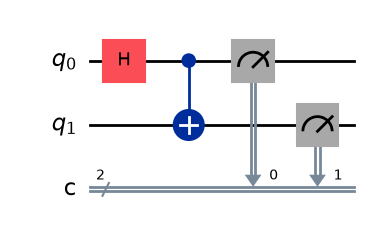

In [5]:

from qiskit import QuantumCircuit

# Original Bell-state circuit
original_circuit = QuantumCircuit(2, 2)

original_circuit.h(0)
original_circuit.cx(0, 1)

# Measure both qubits
original_circuit.measure([0, 1], [0, 1])

display(original_circuit.draw("mpl"))


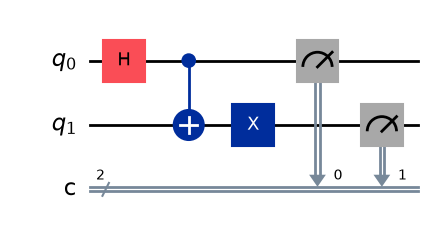

In [6]:

# Modified Bell-state circuit
modified_circuit = QuantumCircuit(2, 2)

modified_circuit.h(0)
modified_circuit.cx(0, 1)

# The single modification: add one X gate
modified_circuit.x(1)

# Measure both qubits
modified_circuit.measure([0, 1], [0, 1])

display(modified_circuit.draw("mpl"))


In [7]:

from qiskit import transpile
from qiskit_ibm_runtime import SamplerV2

circuits = [original_circuit, modified_circuit]

# Compile the circuits for the selected backend
isa_circuits = transpile(
    circuits,
    backend=backend,
    optimization_level=1
)

# Submit both circuits with 100 shots each
sampler = SamplerV2(mode=backend)
job = sampler.run(isa_circuits, shots=100)

print("Job ID:", job.job_id())
print("Waiting for results...")

results = job.result()

# Retrieve actual measurement counts
counts_original = results[0].data.c.get_counts()
counts_modified = results[1].data.c.get_counts()

print("Original Bell circuit:", counts_original)
print("Modified Bell circuit:", counts_modified)


C:\Users\aksha\AppData\Local\Temp\ipykernel_38520\1311035171.py:14: DeprecationWarning: The SamplerV2 class is deprecated as of qiskit-ibm-runtime 0.50.0 and will be removed no sooner than 3 months after the release date. `qiskit_ibm_runtime.executor_sampler.Sampler` provides a new Sampler implementation that runs all the pre- and post-processing in the client side. The top-level `qiskit_ibm_runtime.Sampler` import will be updated to point to the client-side sampler in an upcoming release, with the legacy Sampler being available until the deprecation is completed.
  sampler = SamplerV2(mode=backend)


Job ID: db4ubtklf4us73c39p80
Waiting for results...
Original Bell circuit: {'11': 53, '00': 46, '01': 1}
Modified Bell circuit: {'11': 2, '10': 48, '01': 49, '00': 1}


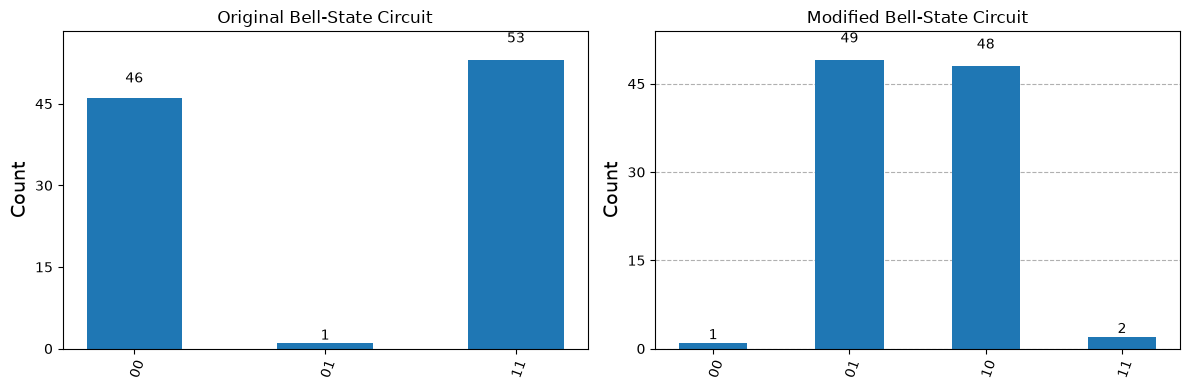

In [8]:

import matplotlib.pyplot as plt
from qiskit.visualization import plot_histogram

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

plot_histogram(
    counts_original,
    ax=axes[0]
)
axes[0].set_title("Original Bell-State Circuit")

plot_histogram(
    counts_modified,
    ax=axes[1]
)
axes[1].set_title("Modified Bell-State Circuit")

plt.tight_layout()
plt.show()


In [9]:

import pandas as pd

comparison = pd.DataFrame({
    "Circuit": [
        "Original Bell circuit",
        "Modified Bell circuit"
    ],
    "Predicted outcomes": [
        "00 and 11",
        "01 and 10"
    ],
    "Actual measurement counts": [
        str(counts_original),
        str(counts_modified)
    ]
})

display(comparison)


,Circuit,Predicted outcomes,Actual measurement counts
0,Original Bell circuit,00 and 11,"{'11': 53, '00': 46, '01': 1}"
1,Modified Bell circuit,01 and 10,"{'11': 2, '10': 48, '01': 49, '00': 1}"
